FRAUD DETECTION

1. INSTALL DEPENDENCIES

In [ ]:
%pip install -U "kagglehub[pandas-datasets]" pandas numpy matplotlib seaborn scikit-learn

2. IMPORT LIBRARIES

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from kagglehub import KaggleDatasetAdapter

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

3. LOAD DATASET DIRECTLY FROM KAGGLE

In [25]:
file_path = "fraudTrain.csv"

df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "kartik2112/fraud-detection",
    file_path
)

print("Dataset loaded successfully!")
print("\nFirst 5 records:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# Confirm necessary columns exist
required_columns = {
    "trans_date_trans_time",
    "amt",
    "is_fraud"
}

missing = required_columns - set(df.columns)

if missing:
    raise ValueError(
        f"Required columns are missing: {missing}"
    )

# Remove unnamed index column if present
df = df.loc[
    :,
    ~df.columns.str.match(r"^Unnamed")
].copy()

# Parse transaction timestamps
df["trans_date_trans_time"] = pd.to_datetime(
    df["trans_date_trans_time"],
    errors="coerce"
)

df["amt"] = pd.to_numeric(
    df["amt"],
    errors="coerce"
)

df["is_fraud"] = pd.to_numeric(
    df["is_fraud"],
    errors="coerce"
)

df = df.dropna(
    subset=["trans_date_trans_time", "amt", "is_fraud"]
).copy()

df["is_fraud"] = df["is_fraud"].astype(int)

assert set(df["is_fraud"].unique()).issubset({0, 1})

print("\nValid rows:", len(df))

Using Colab cache for faster access to the 'fraud-detection' dataset.
Dataset loaded successfully!

First 5 records:
   Unnamed: 0 trans_date_trans_time            cc_num  \
0           0   2019-01-01 00:00:18  2703186189652095   
1           1   2019-01-01 00:00:44      630423337322   
2           2   2019-01-01 00:00:51    38859492057661   
3           3   2019-01-01 00:01:16  3534093764340240   
4           4   2019-01-01 00:03:06   375534208663984   

                             merchant       category     amt      first  \
0          fraud_Rippin, Kub and Mann       misc_net    4.97   Jennifer   
1     fraud_Heller, Gutmann and Zieme    grocery_pos  107.23  Stephanie   
2                fraud_Lind-Buckridge  entertainment  220.11     Edward   
3  fraud_Kutch, Hermiston and Farrell  gas_transport   45.00     Jeremy   
4                 fraud_Keeling-Crist       misc_pos   41.96      Tyler   

      last gender                        street  ...      lat      long  \
0    Banks    

4. ANALYSE CLASS IMBALANCE


Transaction counts:
is_fraud
Legitimate    1289169
Fraud            7506
Name: count, dtype: int64

Class distribution (%):
is_fraud
0    99.421135
1     0.578865
Name: proportion, dtype: float64

Fraud percentage: 0.5789%


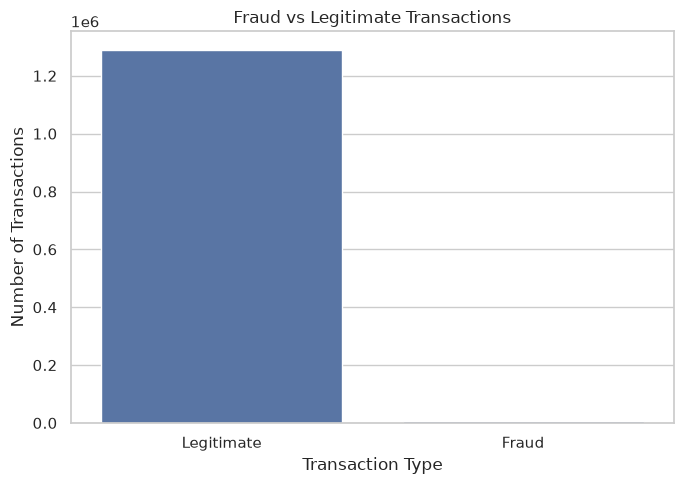

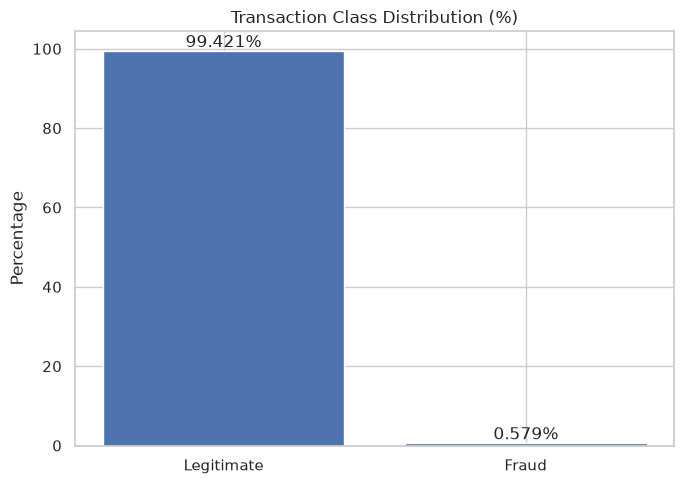

In [26]:
fraud_counts = df["is_fraud"].value_counts()
fraud_percent = df["is_fraud"].value_counts(
    normalize=True
) * 100

print("\nTransaction counts:")
print(fraud_counts.rename(index={
    0: "Legitimate",
    1: "Fraud"
}))

print("\nClass distribution (%):")
print(fraud_percent)

print(
    f"\nFraud percentage: "
    f"{fraud_percent.get(1, 0):.4f}%"
)

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="is_fraud",
    order=[0, 1]
)

ax.set_xticks([0, 1])
ax.set_xticklabels(["Legitimate", "Fraud"])

plt.title("Fraud vs Legitimate Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

# Percentage chart
plt.figure(figsize=(7, 5))

plt.bar(
    ["Legitimate", "Fraud"],
    [
        fraud_percent.get(0, 0),
        fraud_percent.get(1, 0)
    ]
)

plt.title("Transaction Class Distribution (%)")
plt.ylabel("Percentage")

for i, value in enumerate([
    fraud_percent.get(0, 0),
    fraud_percent.get(1, 0)
]):
    plt.text(
        i, value,
        f"{value:.3f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

5. EXPLANATORY DATA ANALYSIS


Transaction amount statistics:
              count        mean         std   min       25%      50%      75%  \
is_fraud                                                                        
0         1289169.0   67.667110  154.007971  1.00    9.6100   47.280   82.540   
1            7506.0  531.320092  390.560070  1.06  245.6625  396.505  900.875   

               max  
is_fraud            
0         28948.90  
1          1376.04  


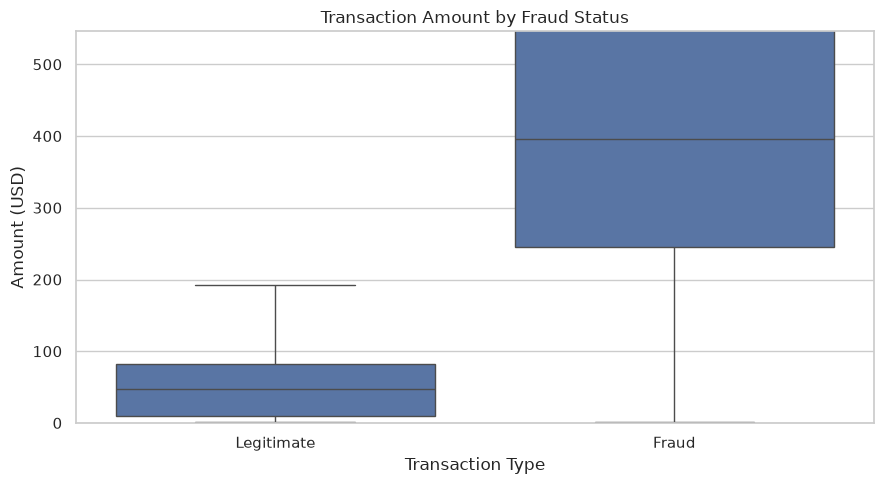

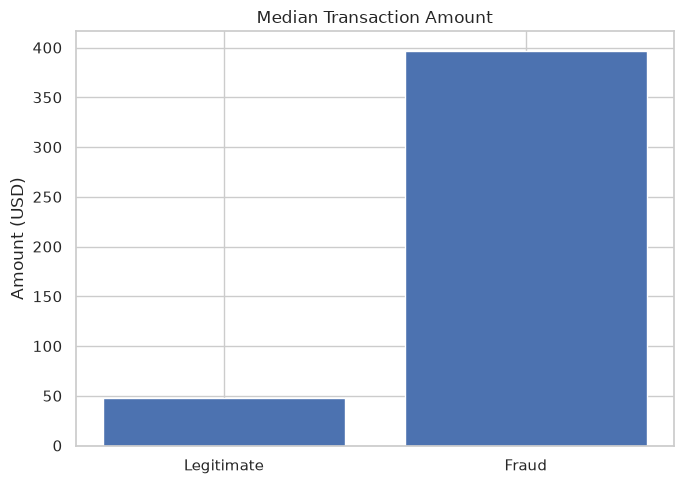

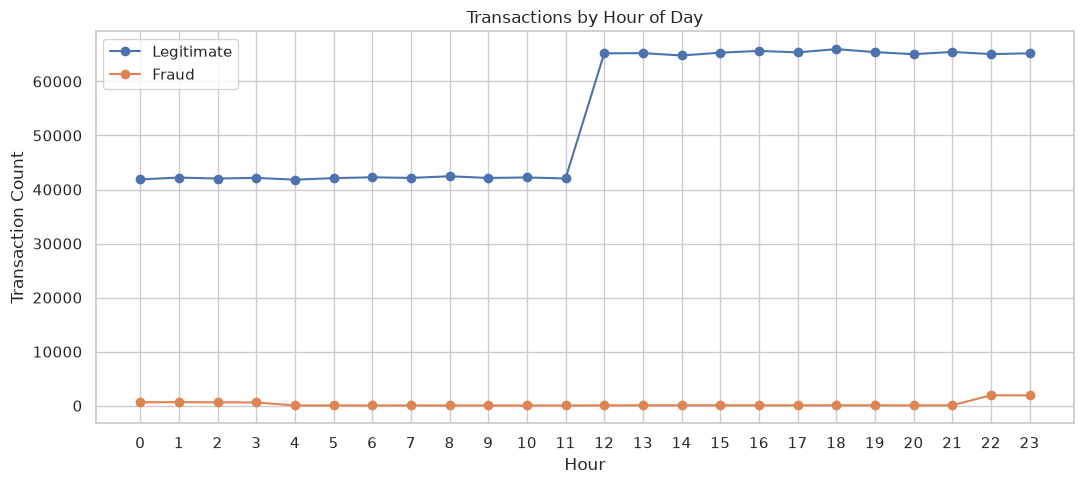

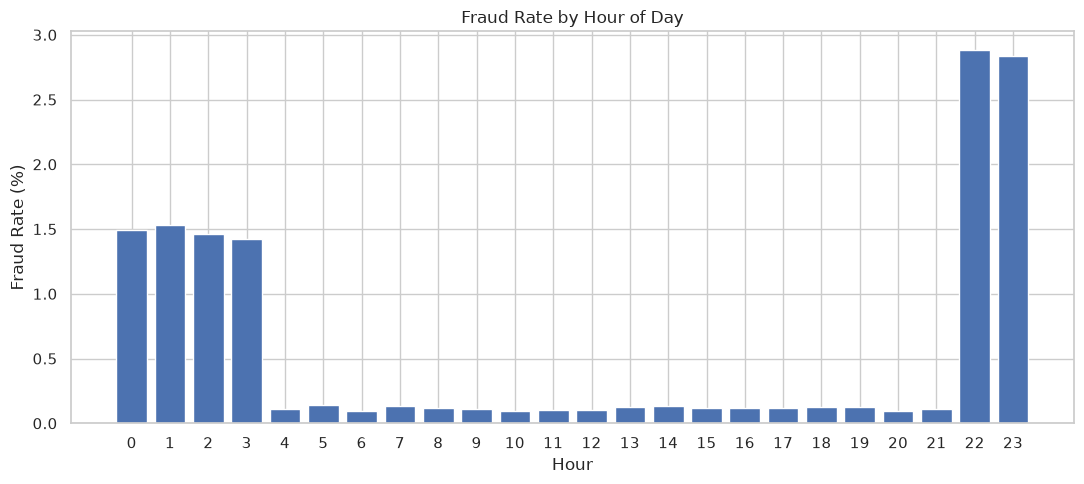


Fraud percentage by hour:
hour
0     1.494
1     1.535
2     1.465
3     1.424
4     0.110
5     0.142
6     0.095
7     0.133
8     0.115
9     0.111
10    0.095
11    0.100
12    0.103
13    0.122
14    0.133
15    0.121
16    0.116
17    0.119
18    0.123
19    0.124
20    0.095
21    0.113
22    2.883
23    2.837
Name: is_fraud, dtype: float64

Fraud by merchant category:
                    mean   sum   count  fraud_rate_pct
category                                              
shopping_net    0.017561  1713   97543        1.756149
misc_net        0.014458   915   63287        1.445795
grocery_pos     0.014098  1743  123638        1.409761
shopping_pos    0.007225   843  116672        0.722538
gas_transport   0.004694   618  131659        0.469394
misc_pos        0.003139   250   79655        0.313853
grocery_net     0.002948   134   45452        0.294817
travel          0.002864   116   40507        0.286370
entertainment   0.002478   233   94014        0.247835
personal_care  

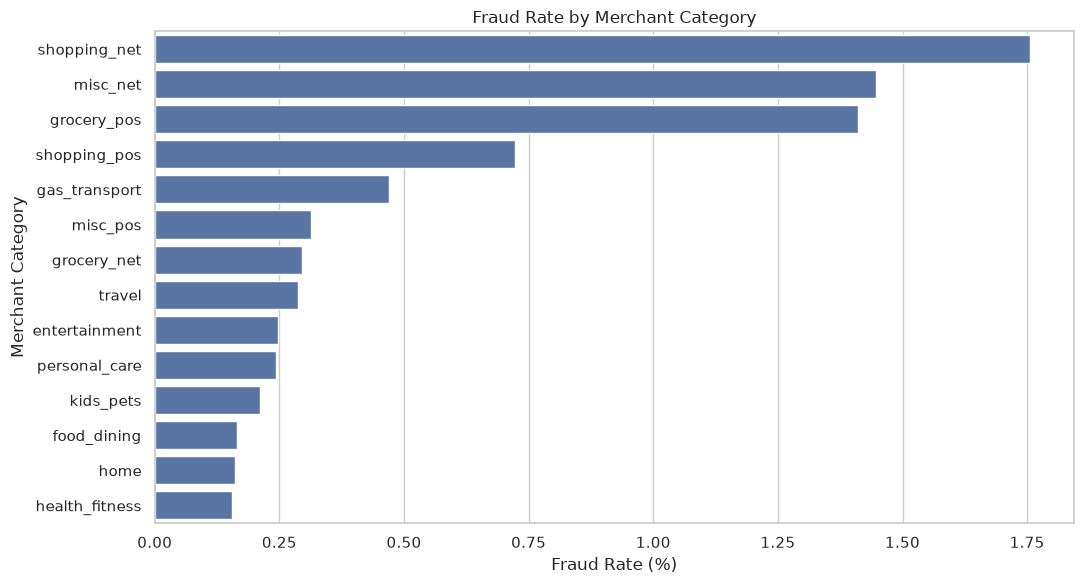

In [27]:
# A: Transaction amounts for fraud vs non-fraud

print("\nTransaction amount statistics:")
print(
    df.groupby("is_fraud")["amt"].describe()
)

# Boxplot with 99th percentile as display limit
# All data remains unchanged for model training.
display_limit = df["amt"].quantile(0.99)

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="is_fraud",
    y="amt",
    order=[0, 1],
    showfliers=False
)

plt.ylim(0, display_limit)
plt.xticks([0, 1], ["Legitimate", "Fraud"])

plt.title("Transaction Amount by Fraud Status")
plt.xlabel("Transaction Type")
plt.ylabel("Amount (USD)")

plt.tight_layout()
plt.show()

# Median transaction amount
median_amounts = df.groupby(
    "is_fraud"
)["amt"].median()

plt.figure(figsize=(7, 5))

plt.bar(
    ["Legitimate", "Fraud"],
    [
        median_amounts.get(0, 0),
        median_amounts.get(1, 0)
    ]
)

plt.title("Median Transaction Amount")
plt.ylabel("Amount (USD)")
plt.tight_layout()
plt.show()

# B: Time-of-day analysis

df["hour"] = df[
    "trans_date_trans_time"
].dt.hour

df["day_of_week"] = df[
    "trans_date_trans_time"
].dt.dayofweek

df["month"] = df[
    "trans_date_trans_time"
].dt.month

# Number of fraud transactions by hour
hourly_counts = pd.crosstab(
    df["hour"],
    df["is_fraud"]
).reindex(
    index=range(24),
    columns=[0, 1],
    fill_value=0
)

plt.figure(figsize=(11, 5))

plt.plot(
    hourly_counts.index,
    hourly_counts[0],
    label="Legitimate",
    marker="o"
)

plt.plot(
    hourly_counts.index,
    hourly_counts[1],
    label="Fraud",
    marker="o"
)

plt.title("Transactions by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Transaction Count")
plt.xticks(range(24))
plt.legend()

plt.tight_layout()
plt.show()

# More meaningful for imbalanced data:
# fraud rate by hour, not just absolute count.

hourly_rate = (
    df.groupby("hour")["is_fraud"].mean() * 100
).reindex(range(24), fill_value=0)

plt.figure(figsize=(11, 5))

plt.bar(
    hourly_rate.index,
    hourly_rate.values
)

plt.title("Fraud Rate by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Fraud Rate (%)")
plt.xticks(range(24))

plt.tight_layout()
plt.show()

print("\nFraud percentage by hour:")
print(hourly_rate.round(3))

# C: Fraud rate by merchant category
if "category" in df.columns:

    category_fraud = (
        df.groupby("category")["is_fraud"]
        .agg(["mean", "sum", "count"])
        .sort_values("mean", ascending=False)
    )

    category_fraud["fraud_rate_pct"] = (
        category_fraud["mean"] * 100
    )

    print("\nFraud by merchant category:")
    print(category_fraud)

    plt.figure(figsize=(11, 6))

    sns.barplot(
        x=category_fraud["fraud_rate_pct"],
        y=category_fraud.index
    )

    plt.title("Fraud Rate by Merchant Category")
    plt.xlabel("Fraud Rate (%)")
    plt.ylabel("Merchant Category")

    plt.tight_layout()
    plt.show()

6. FEATURE EXTRACTION

In [28]:
# Age at the date of transaction
if "dob" in df.columns:

    df["dob"] = pd.to_datetime(
        df["dob"],
        errors="coerce"
    )

    df["age"] = (
        (
            df["trans_date_trans_time"] - df["dob"]
        ).dt.days / 365.25
    )

    df.loc[
        ~df["age"].between(0, 110),
        "age"
    ] = np.nan

# Approximate customer-to-merchant distance in km
# using the Haversine formula.

geo_cols = [
    "lat", "long",
    "merch_lat", "merch_long"
]

if all(c in df.columns for c in geo_cols):

    coords = df[geo_cols].apply(
        pd.to_numeric,
        errors="coerce"
    )

    lat1 = np.radians(coords["lat"])
    lon1 = np.radians(coords["long"])
    lat2 = np.radians(coords["merch_lat"])
    lon2 = np.radians(coords["merch_long"])

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    a = a.clip(0, 1)

    df["distance_km"] = (
        6371 * 2 * np.arcsin(np.sqrt(a))
    )

# Cyclical encoding for hour of day
df["hour_sin"] = np.sin(
    2 * np.pi * df["hour"] / 24
)

df["hour_cos"] = np.cos(
    2 * np.pi * df["hour"] / 24
)

df["log_amt"] = np.log1p(
    df["amt"].clip(lower=0)
)


7. SELECT MODEL FEATURES

In [29]:
numeric_features = [
    "amt",
    "log_amt",
    "hour_sin",
    "hour_cos",
    "day_of_week",
    "month",
    "city_pop",
    "age",
    "distance_km"
]

categorical_features = [
    "category",
    "gender",
    "state"
]

# Keep only features present in the source data
numeric_features = [
    col for col in numeric_features
    if col in df.columns
]

categorical_features = [
    col for col in categorical_features
    if col in df.columns
]

feature_columns = (
    numeric_features + categorical_features
)

print("\nSelected features:")
print(feature_columns)

# Sensitive identifiers and potentially
# memorisation-prone fields are deliberately
# excluded: credit card number, names,
# transaction ID, customer address, etc.


Selected features:
['amt', 'log_amt', 'hour_sin', 'hour_cos', 'day_of_week', 'month', 'city_pop', 'age', 'distance_km', 'category', 'gender', 'state']


8. STRATIFIED SAMPLE (OPTIONAL)

In [30]:
# Set to None to use the full dataset.
# 150000 is useful for a normal laptop.

SAMPLE_SIZE = 150000

if SAMPLE_SIZE is not None and len(df) > SAMPLE_SIZE:

    df_model, unused_df = train_test_split(
        df,
        train_size=SAMPLE_SIZE,
        stratify=df["is_fraud"],
        random_state=RANDOM_STATE
    )

    del unused_df

else:
    df_model = df

print("\nRows used for modelling:", len(df_model))

print("\nModel sample fraud distribution:")
print(
    df_model["is_fraud"]
    .value_counts(normalize=True) * 100
)

X = df_model[feature_columns].copy()
y = df_model["is_fraud"].copy()



Rows used for modelling: 150000

Model sample fraud distribution:
is_fraud
0    99.421333
1     0.578667
Name: proportion, dtype: float64


9. STRATIFIED TRAIN/TEST SPLIT

In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class counts:")
print(y_train.value_counts())

print("\nTesting class counts:")
print(y_test.value_counts())

assert y_train.nunique() == 2
assert y_test.nunique() == 2


Training samples: 120000
Testing samples: 30000

Training class counts:
is_fraud
0    119306
1       694
Name: count, dtype: int64

Testing class counts:
is_fraud
0    29826
1      174
Name: count, dtype: int64


10. HANDLE MISSING VALUES AND CATEGORICAL DATA

In [32]:
numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

def make_preprocessor():

    return ColumnTransformer(
        transformers=[
            (
                "num",
                numeric_transformer,
                numeric_features
            ),
            (
                "cat",
                categorical_transformer,
                categorical_features
            )
        ]
    )

# IMPORTANT:
# Preprocessing is fitted only on training data.
# This avoids leakage from the test set.

11. EXPLAIN AND HANDLE CLASS IMBALANCE

In [33]:
print("\nCLASS IMBALANCE EXPLANATION")
print(
    "Fraud is rare compared with legitimate transactions."
)
print(
    "A model predicting every transaction as legitimate "
    "can obtain high accuracy while detecting zero fraud."
)
print(
    "Therefore, we evaluate precision, recall, F1 "
    "and ROC-AUC instead of relying on accuracy."
)

# Technique: class_weight='balanced'
# This increases the training penalty for errors
# on the minority fraud class.
# We do not apply SMOTE to the test set.


CLASS IMBALANCE EXPLANATION
Fraud is rare compared with legitimate transactions.
A model predicting every transaction as legitimate can obtain high accuracy while detecting zero fraud.
Therefore, we evaluate precision, recall, F1 and ROC-AUC instead of relying on accuracy.


12. TRAIN LOGISTIC REGRESSION

In [34]:
logistic_model = Pipeline(
    steps=[
        (
            "preprocessor",
            make_preprocessor()
        ),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                solver="lbfgs",
                random_state=RANDOM_STATE
            )
        )
    ]
)

print("\nTraining Logistic Regression...")

logistic_model.fit(X_train, y_train)

print("Logistic Regression trained.")



Training Logistic Regression...
Logistic Regression trained.


13. TRAIN RANDOM FOREST

In [35]:
rf_model = Pipeline(
    steps=[
        (
            "preprocessor",
            make_preprocessor()
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=100,
                max_depth=16,
                min_samples_leaf=2,
                class_weight="balanced_subsample",
                random_state=RANDOM_STATE,
                n_jobs=-1
            )
        )
    ]
)

print("\nTraining Random Forest...")

rf_model.fit(X_train, y_train)

print("Random Forest trained.")


Training Random Forest...
Random Forest trained.


14. EVALUATE BOTH MODELS

In [36]:
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model
}

results = []
predictions = {}
probabilities = {}

for name, model in models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    predictions[name] = y_pred
    probabilities[name] = y_prob

    metrics_row = {
        "Model": name,
        "Accuracy": accuracy_score(
            y_test, y_pred
        ),
        "Precision": precision_score(
            y_test, y_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred,
            zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred,
            zero_division=0
        ),
        "ROC_AUC": roc_auc_score(
            y_test, y_prob
        ),
        "PR_AUC": average_precision_score(
            y_test, y_prob
        )
    }

    results.append(metrics_row)

    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=[
                "Legitimate",
                "Fraud"
            ],
            zero_division=0
        )
    )

    print("ROC-AUC:", round(
        metrics_row["ROC_AUC"], 4
    ))

    print("PR-AUC:", round(
        metrics_row["PR_AUC"], 4
    ))

results_df = pd.DataFrame(results)

print("\nFINAL MODEL COMPARISON")
print(results_df.round(4).to_string(index=False))


Logistic Regression
              precision    recall  f1-score   support

  Legitimate       1.00      0.90      0.95     29826
       Fraud       0.05      0.89      0.10       174

    accuracy                           0.90     30000
   macro avg       0.53      0.89      0.52     30000
weighted avg       0.99      0.90      0.94     30000

ROC-AUC: 0.9632
PR-AUC: 0.254

Random Forest
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     29826
       Fraud       0.62      0.82      0.71       174

    accuracy                           1.00     30000
   macro avg       0.81      0.91      0.85     30000
weighted avg       1.00      1.00      1.00     30000

ROC-AUC: 0.9897
PR-AUC: 0.825

FINAL MODEL COMPARISON
              Model  Accuracy  Precision  Recall     F1  ROC_AUC  PR_AUC
Logistic Regression    0.9040     0.0511  0.8851 0.0966   0.9632   0.254
      Random Forest    0.9961     0.6245  0.8218 0.7097   0.9897   0.825


15. CONFUSION MATRICES

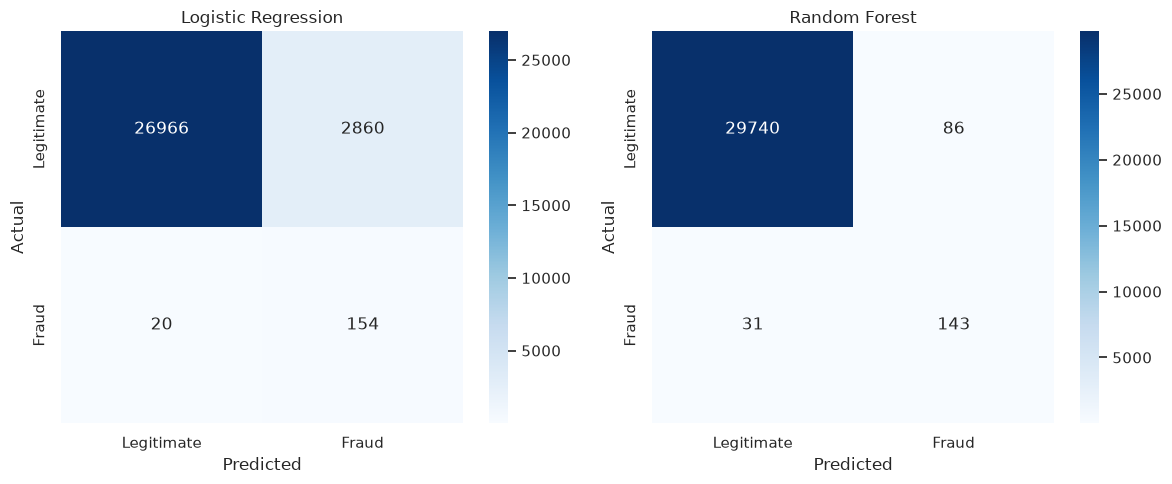

In [37]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

for ax, (name, y_pred) in zip(
    axes,
    predictions.items()
):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=[
            "Legitimate", "Fraud"
        ],
        yticklabels=[
            "Legitimate", "Fraud"
        ],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

16. ROC CURVES

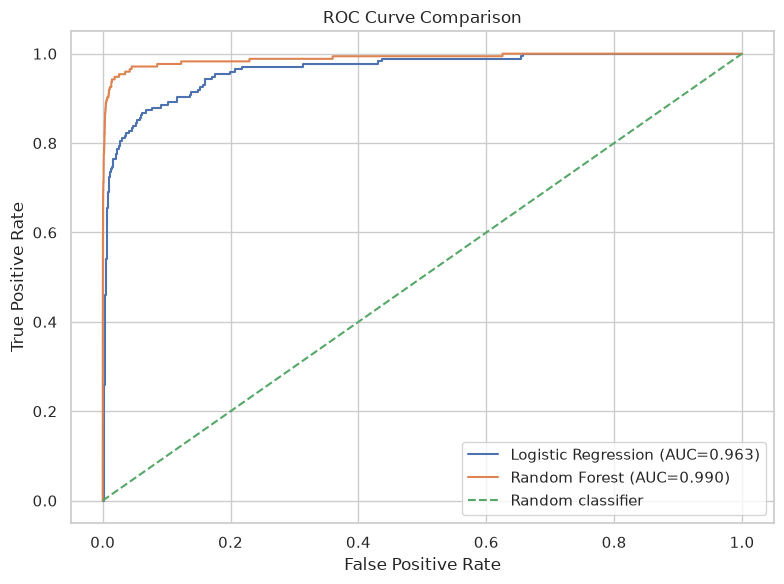

In [38]:
plt.figure(figsize=(8, 6))

for name, y_prob in probabilities.items():

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_prob
    )

    auc_value = roc_auc_score(
        y_test,
        y_prob
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={auc_value:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Random classifier"
)

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.tight_layout()
plt.show()


17. PRECISION-RECALL CURVES

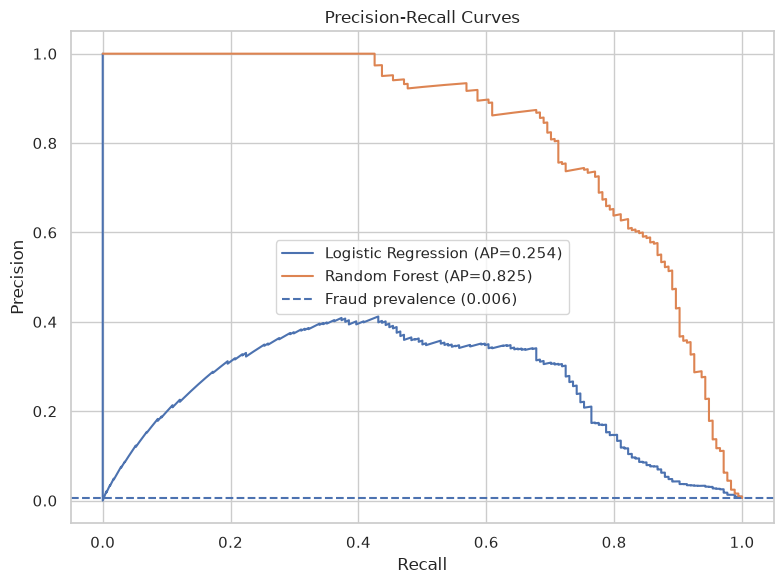

In [39]:
plt.figure(figsize=(8, 6))

for name, y_prob in probabilities.items():

    precision, recall, thresholds = (
        precision_recall_curve(
            y_test,
            y_prob
        )
    )

    ap = average_precision_score(
        y_test,
        y_prob
    )

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP={ap:.3f})"
    )

baseline = y_test.mean()

plt.axhline(
    baseline,
    linestyle="--",
    label=f"Fraud prevalence ({baseline:.3f})"
)

plt.title("Precision-Recall Curves")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()

plt.tight_layout()
plt.show()


PRECISION VS RECALL TRADE-OFF

In [40]:
# Changing the probability threshold changes
# the number of transactions flagged as fraud.
# Show the trade-off for each model.

threshold_rows = []

for name, y_prob in probabilities.items():

    for threshold in [0.2, 0.3, 0.5, 0.7, 0.9]:

        predicted = (
            y_prob >= threshold
        ).astype(int)

        threshold_rows.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_test,
                predicted,
                zero_division=0
            ),
            "Recall": recall_score(
                y_test,
                predicted,
                zero_division=0
            ),
            "F1": f1_score(
                y_test,
                predicted,
                zero_division=0
            ),
            "Alerts": int(predicted.sum())
        })

threshold_df = pd.DataFrame(
    threshold_rows
)

print("\nTHRESHOLD ANALYSIS")
print(
    threshold_df.round(4).to_string(
        index=False
    )
)

print(
    "\nLower thresholds usually increase recall "
    "but generate more false-positive alerts."
)

print(
    "Higher thresholds usually increase precision "
    "but may miss more fraudulent transactions."
)


THRESHOLD ANALYSIS
              Model  Threshold  Precision  Recall     F1  Alerts
Logistic Regression        0.2     0.0178  0.9770 0.0349    9577
Logistic Regression        0.3     0.0242  0.9713 0.0473    6973
Logistic Regression        0.5     0.0511  0.8851 0.0966    3014
Logistic Regression        0.7     0.1434  0.8046 0.2435     976
Logistic Regression        0.9     0.3132  0.6839 0.4296     380
      Random Forest        0.2     0.1522  0.9540 0.2625    1091
      Random Forest        0.3     0.2539  0.9425 0.4000     646
      Random Forest        0.5     0.6245  0.8218 0.7097     229
      Random Forest        0.7     0.8702  0.6552 0.7475     131
      Random Forest        0.9     1.0000  0.4080 0.5796      71

Lower thresholds usually increase recall but generate more false-positive alerts.
Higher thresholds usually increase precision but may miss more fraudulent transactions.


19. RANDOM FOREST FEATURE IMPORTANCE


TOP 20 RANDOM FOREST FEATURES
                        Feature  Importance
0                      num__amt    0.302825
1                  num__log_amt    0.273957
3                 num__hour_cos    0.140381
2                 num__hour_sin    0.054453
7                      num__age    0.023307
8              num__distance_km    0.020020
6                 num__city_pop    0.017876
5                    num__month    0.015981
20   cat__category_shopping_net    0.013006
11  cat__category_gas_transport    0.012827
13    cat__category_grocery_pos    0.010520
4              num__day_of_week    0.010368
10    cat__category_food_dining    0.009652
15           cat__category_home    0.007181
17       cat__category_misc_net    0.006800
21   cat__category_shopping_pos    0.006314
16      cat__category_kids_pets    0.006123
22         cat__category_travel    0.004840
9   cat__category_entertainment    0.004642
18       cat__category_misc_pos    0.004565


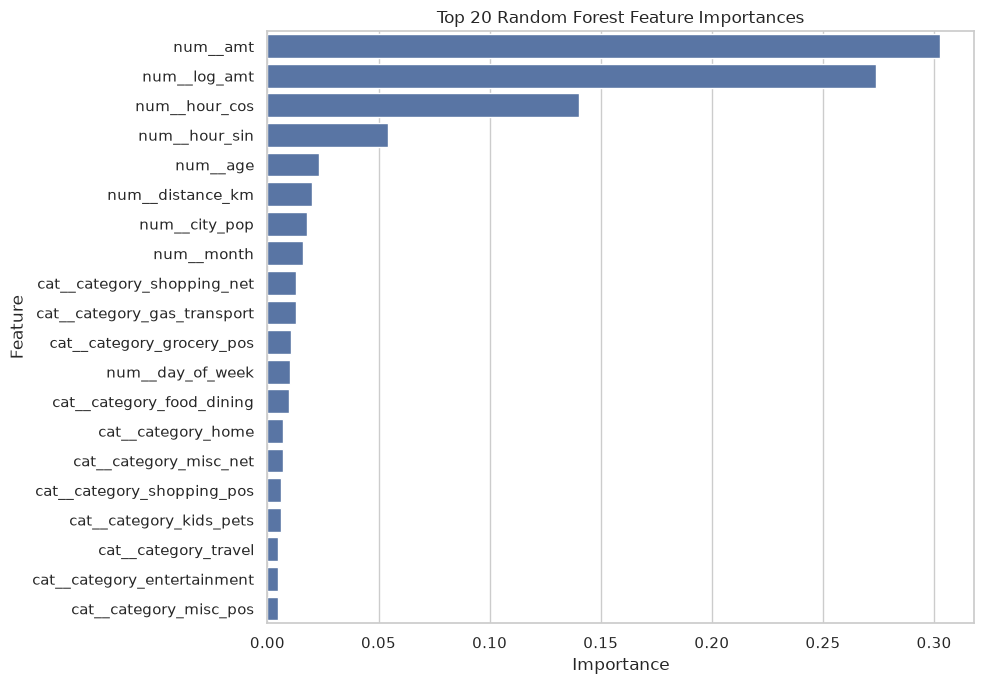

In [41]:
rf_preprocessor = rf_model.named_steps[
    "preprocessor"
]

rf_classifier = rf_model.named_steps[
    "classifier"
]

rf_feature_names = (
    rf_preprocessor.get_feature_names_out()
)

rf_importance_df = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": (
        rf_classifier.feature_importances_
    )
}).sort_values(
    "Importance",
    ascending=False
)

print("\nTOP 20 RANDOM FOREST FEATURES")
print(rf_importance_df.head(20))

plt.figure(figsize=(10, 7))

sns.barplot(
    data=rf_importance_df.head(20),
    x="Importance",
    y="Feature"
)

plt.title("Top 20 Random Forest Feature Importances")
plt.tight_layout()
plt.show()


20. LOGISTIC REGRESSION COEFFICIENTS


TOP 20 LOGISTIC REGRESSION COEFFICIENTS
                         Feature  Coefficient  Absolute_Coefficient
20    cat__category_shopping_net    -6.010407              6.010407
21    cat__category_shopping_pos    -4.613302              4.613302
17        cat__category_misc_net    -3.508786              3.508786
0                       num__amt     2.819512              2.819512
31                 cat__state_CT    -2.384758              2.384758
38                 cat__state_ID    -2.235128              2.235128
28                 cat__state_AZ    -2.135333              2.135333
19   cat__category_personal_care     2.111133              2.111133
11   cat__category_gas_transport     1.990285              1.990285
32                 cat__state_DC    -1.962920              1.962920
16       cat__category_kids_pets     1.691648              1.691648
12     cat__category_grocery_net     1.667406              1.667406
10     cat__category_food_dining     1.658159              1.658159
13     

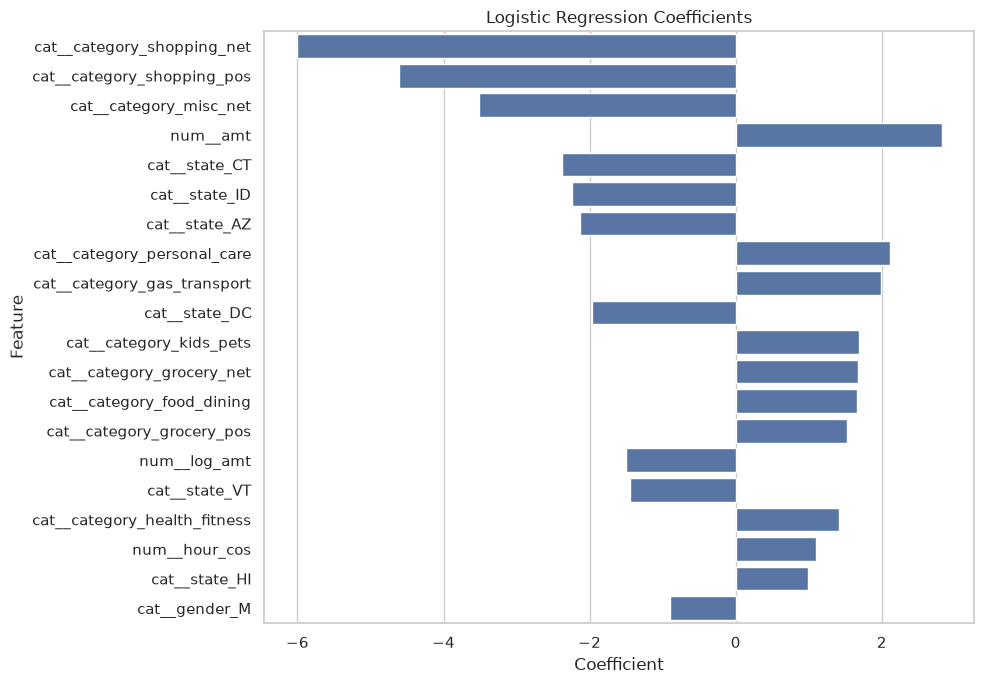


Note: Coefficients represent associations in the fitted model, not causal effects.


In [42]:
lr_preprocessor = logistic_model.named_steps[
    "preprocessor"
]

lr_classifier = logistic_model.named_steps[
    "classifier"
]

lr_feature_names = (
    lr_preprocessor.get_feature_names_out()
)

lr_coef_df = pd.DataFrame({
    "Feature": lr_feature_names,
    "Coefficient": lr_classifier.coef_[0]
})

lr_coef_df["Absolute_Coefficient"] = (
    lr_coef_df["Coefficient"].abs()
)

lr_coef_df = lr_coef_df.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

print("\nTOP 20 LOGISTIC REGRESSION COEFFICIENTS")
print(lr_coef_df.head(20))

plt.figure(figsize=(10, 7))

sns.barplot(
    data=lr_coef_df.head(20),
    x="Coefficient",
    y="Feature"
)

plt.title("Logistic Regression Coefficients")
plt.tight_layout()
plt.show()

print(
    "\nNote: Coefficients represent associations "
    "in the fitted model, not causal effects."
)


21. DETERMINE BEST MODEL

In [43]:
# Selection criterion: F1 at default threshold.
# This balances precision and recall.
# Business requirements could favour recall
# or precision instead.

best_row = results_df.sort_values(
    ["F1", "PR_AUC"],
    ascending=False
).iloc[0]

best_name = best_row["Model"]

print("\nBEST MODEL BY F1:")
print(best_name)

print("\nBest model metrics:")
print(best_row.to_string())


BEST MODEL BY F1:
Random Forest

Best model metrics:
Model        Random Forest
Accuracy            0.9961
Precision         0.624454
Recall            0.821839
F1                0.709677
ROC_AUC           0.989748
PR_AUC            0.824976


22. SCALABILITY DISCUSSION

In [44]:
transactions_per_hour = 1_000_000

print("\nSCALABILITY DISCUSSION")
print("=" * 55)

print(
    "Target throughput:",
    f"{transactions_per_hour:,} transactions/hour"
)

print(
    "Average throughput:",
    f"{transactions_per_hour / 3600:.2f}",
    "transactions/second"
)

print("""
A real-world fraud detection platform could use:

1. Streaming ingestion:
   Apache Kafka or another message queue.

2. Real-time feature processing:
   Process incoming transactions and construct
   model features consistently.

3. Model serving:
   Deploy a saved preprocessing + model pipeline
   behind a prediction API such as FastAPI.

4. Batch scoring:
   Use vectorised inference for groups of transactions
   where real-time responses are not essential.

5. Scaling:
   Use multiple model-serving instances with
   load balancing and horizontal autoscaling.

6. Monitoring:
   Track latency, throughput, data drift,
   fraud recall, precision and false alerts.

7. Retraining:
   Periodically train using newly confirmed,
   correctly labelled fraud cases.

8. Security and privacy:
   Avoid exposing sensitive customer identifiers,
   restrict access, and audit predictions.

The target averages roughly 278 transactions
per second, but peak load could be considerably
higher. Actual capacity must be benchmarked.

This notebook trains an offline prototype;
it does not demonstrate production throughput.
""")



SCALABILITY DISCUSSION
Target throughput: 1,000,000 transactions/hour
Average throughput: 277.78 transactions/second

A real-world fraud detection platform could use:

1. Streaming ingestion:
   Apache Kafka or another message queue.

2. Real-time feature processing:
   Process incoming transactions and construct
   model features consistently.

3. Model serving:
   Deploy a saved preprocessing + model pipeline
   behind a prediction API such as FastAPI.

4. Batch scoring:
   Use vectorised inference for groups of transactions
   where real-time responses are not essential.

5. Scaling:
   Use multiple model-serving instances with
   load balancing and horizontal autoscaling.

6. Monitoring:
   Track latency, throughput, data drift,
   fraud recall, precision and false alerts.

7. Retraining:
   Periodically train using newly confirmed,
   correctly labelled fraud cases.

8. Security and privacy:
   Avoid exposing sensitive customer identifiers,
   restrict access, and audit predictio

23. FINAL PROJECT SUMMARY

In [45]:
print("\nPROJECT CONCLUSION")
print("=" * 55)

print(
    "Rows used:", len(df_model)
)

print(
    "Fraud rate in full dataset:",
    f"{df['is_fraud'].mean() * 100:.4f}%"
)

print(
    "Imbalance technique:",
    "Class-weight balancing"
)

print(
    "Models:",
    ", ".join(models.keys())
)

print(
    "Best model by test F1:",
    best_name
)

print(
    "Best-model F1:",
    round(float(best_row["F1"]), 4)
)

print(
    "Best-model ROC-AUC:",
    round(float(best_row["ROC_AUC"]), 4)
)

print(
    "Best-model PR-AUC:",
    round(float(best_row["PR_AUC"]), 4)
)

print("""
Final recommendation:
Use recall to assess how many fraudulent
transactions are caught, and precision to
assess how many flagged transactions are
actually fraudulent.

Select an alert threshold using business
costs and a separate validation dataset
before deploying the model.

This analysis is for an internship project,
not a production-ready fraud detection service.
""")

# Save the comparison results
results_df.to_csv(
    "fraud_model_comparison.csv",
    index=False
)

rf_importance_df.to_csv(
    "fraud_feature_importance.csv",
    index=False
)

print("\nResults saved successfully.")



PROJECT CONCLUSION
Rows used: 150000
Fraud rate in full dataset: 0.5789%
Imbalance technique: Class-weight balancing
Models: Logistic Regression, Random Forest
Best model by test F1: Random Forest
Best-model F1: 0.7097
Best-model ROC-AUC: 0.9897
Best-model PR-AUC: 0.825

Final recommendation:
Use recall to assess how many fraudulent
transactions are caught, and precision to
assess how many flagged transactions are
actually fraudulent.

Select an alert threshold using business
costs and a separate validation dataset
before deploying the model.

This analysis is for an internship project,
not a production-ready fraud detection service.


Results saved successfully.
